<a href="https://colab.research.google.com/github/Sooniixx/pattern-recognition-practice/blob/main/notebooks/PR02_Fesenko_Sofiia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 2
## Дослідницький аналіз і підготовка даних
**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студентка:** Софія Фесенко  
**Група:** ІН-32  
**Дата виконання:** 2026-12-10  

### Мета роботи
Навчитися досліджувати структуру та якість табличних даних, виявляти й усувати пропущені значення, дублікати, неправильні типи даних і аномальні значення, кодувати категоріальні ознаки та формувати навчальну й тестову вибірки для подальшого навчання моделей машинного навчання.

## 1. Підключення бібліотек

In [14]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from IPython.display import display

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16
NumPy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.6.1


## 2. Підключення Google Drive і створення шляхів

In [15]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

SOURCE_PATH = DATA_DIR / "iris.csv"
DIRTY_PATH = DATA_DIR / "iris_dirty.csv"
CLEANED_PATH = PROCESSED_DIR / "iris_cleaned.csv"
X_TRAIN_PATH = PROCESSED_DIR / "X_train.csv"
X_TEST_PATH = PROCESSED_DIR / "X_test.csv"
Y_TRAIN_PATH = PROCESSED_DIR / "y_train.csv"
Y_TEST_PATH = PROCESSED_DIR / "y_test.csv"
SUMMARY_PATH = REPORTS_DIR / "preprocessing_summary.csv"
CLASS_MAPPING_PATH = REPORTS_DIR / "class_mapping.json"

DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Папка проєкту:", PROJECT_DIR)
print("Папка початкових даних:", DATA_DIR)
print("Папка підготовлених даних:", PROCESSED_DIR)
print("Папка звітів:", REPORTS_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Папка проєкту: /content/drive/MyDrive/pattern-recognition-practice
Папка початкових даних: /content/drive/MyDrive/pattern-recognition-practice/data
Папка підготовлених даних: /content/drive/MyDrive/pattern-recognition-practice/data/processed
Папка звітів: /content/drive/MyDrive/pattern-recognition-practice/reports


## 3. Завантаження початкового набору Iris та створення пошкодженої версії

In [16]:
if SOURCE_PATH.exists():
    source_df = pd.read_csv(SOURCE_PATH)
    print("Початковий файл завантажено з Google Drive.")
else:
    print("Файл iris.csv не знайдено. Створюємо його повторно.")
    iris = load_iris(as_frame=True)
    source_df = iris.frame.copy()
    source_df["species"] = source_df["target"].map({
        0: "setosa",
        1: "versicolor",
        2: "virginica"
    })
    source_df = source_df.drop(columns=["target"])
    source_df = source_df.rename(
        columns={
            "sepal length (cm)": "sepal_length_cm",
            "sepal width (cm)": "sepal_width_cm",
            "petal length (cm)": "petal_length_cm",
            "petal width (cm)": "petal_width_cm"
        }
    )
    source_df.to_csv(SOURCE_PATH, index=False)

rng = np.random.default_rng(42)
dirty_df = source_df.copy()

#  категоріальна ознаку пристрою
dirty_df["measurement_device"] = rng.choice(
    ["device_a", "device_b", "device_c"],
    size=len(dirty_df),
    p=[0.40, 0.35, 0.25]
)

# Пропуски
missing_plan = {
    "sepal_length_cm": 4,
    "sepal_width_cm": 5,
    "petal_length_cm": 4,
    "petal_width_cm": 5,
    "measurement_device": 4,
    "species": 2
}
for column, amount in missing_plan.items():
    selected_indices = rng.choice(dirty_df.index, size=amount, replace=False)
    dirty_df.loc[selected_indices, column] = np.nan

# Перетворення типу стовпця на object та внесення «сміття»
dirty_df["sepal_length_cm"] = dirty_df["sepal_length_cm"].astype("object")
dirty_df.loc[3, "sepal_length_cm"] = "5,1"
dirty_df.loc[25, "sepal_length_cm"] = "unknown"
dirty_df.loc[47, "sepal_length_cm"] = "  6.3"

# Неузгоджені назви категорій
dirty_df.loc[19, "measurement_device"] = "DEVICE B"
dirty_df.loc[7, "measurement_device"] = "Device A"
dirty_df.loc[52, "measurement_device"] = "device c"

# Фізично неможливі та аномальні значення
dirty_df.loc[33, "petal_length_cm"] = -1.0
dirty_df.loc[10, "sepal_width_cm"] = 18.0
dirty_df.loc[55, "petal_width_cm"] = 9.5

# Дублікати
duplicate_rows = dirty_df.iloc[[6, 27, 50, 88]].copy()
dirty_df = pd.concat([dirty_df, duplicate_rows], ignore_index=True)

dirty_df.to_csv(DIRTY_PATH, index=False)
print("Пошкоджений набір створено:", DIRTY_PATH)
print("Розмір:", dirty_df.shape)

raw_df = pd.read_csv(DIRTY_PATH)
display(raw_df.head())

Початковий файл завантажено з Google Drive.
Пошкоджений набір створено: /content/drive/MyDrive/pattern-recognition-practice/data/iris_dirty.csv
Розмір: (154, 6)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,measurement_device
0,5.1,3.5,1.4,0.2,setosa,device_c
1,NaN,3.0,1.4,0.2,setosa,device_b
2,4.7,3.2,1.3,0.2,setosa,device_c
3,"5,1",3.1,1.5,0.2,setosa,device_b
4,5.0,3.6,1.4,0.2,setosa,device_a


## 4. Початковий аудит якості даних

In [17]:
raw_df.info()

quality_report = pd.DataFrame(
    {
        "data_type": raw_df.dtypes.astype(str),
        "missing_count": raw_df.isna().sum(),
        "missing_percent": raw_df.isna().mean().mul(100).round(2),
        "unique_count": raw_df.nunique(dropna=True)
    }
)
display(quality_report)

# Повний цикл пошуку невалідних числових значень
numeric_columns = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm"
]

invalid_numeric_summary = []
for column in numeric_columns:
    prepared_text = (
        raw_df[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )
    converted_values = pd.to_numeric(
        prepared_text,
        errors="coerce"
    )
    invalid_mask = (
        prepared_text.notna()
        & converted_values.isna()
    )
    invalid_numeric_summary.append(
        {
            "column": column,
            "invalid_count": int(invalid_mask.sum()),
            "invalid_values": raw_df.loc[
                invalid_mask,
                column
            ].astype(str).tolist()
        }
    )

invalid_numeric_summary_df = pd.DataFrame(invalid_numeric_summary)
display(invalid_numeric_summary_df)

# Перегляд унікальних категорій пристрою з repr()
print("\nПочаткові варіанти measurement_device:")
for value in raw_df["measurement_device"].dropna().unique():
    print(repr(value))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sepal_length_cm     150 non-null    object 
 1   sepal_width_cm      149 non-null    float64
 2   petal_length_cm     150 non-null    float64
 3   petal_width_cm      149 non-null    float64
 4   species             152 non-null    object 
 5   measurement_device  150 non-null    object 
dtypes: float64(3), object(3)
memory usage: 7.3+ KB


,data_type,missing_count,missing_percent,unique_count
sepal_length_cm,object,4,2.60,38
sepal_width_cm,float64,5,3.25,24
petal_length_cm,float64,4,2.60,43
petal_width_cm,float64,5,3.25,23
species,object,2,1.30,3
measurement_device,object,4,2.60,6


,column,invalid_count,invalid_values
0,sepal_length_cm,1,[unknown]
1,sepal_width_cm,0,[]
2,petal_length_cm,0,[]
3,petal_width_cm,0,[]



Початкові варіанти measurement_device:
'device_c'
'device_b'
'device_a'
'Device A'
'DEVICE B'
'device c'


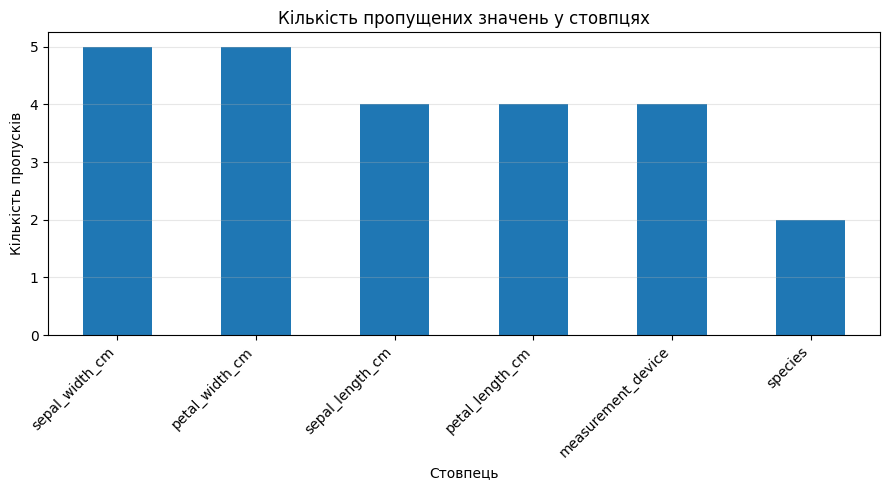

Кількість додаткових дублікатів: 4
Кількість рядків у групах дублікатів: 8


In [18]:
missing_report = pd.DataFrame(
    {
        "missing_count": raw_df.isna().sum(),
        "missing_percent": raw_df.isna().mean().mul(100).round(2)
    }
).sort_values(by="missing_count", ascending=False)

missing_report["missing_count"].plot(kind="bar", figsize=(9, 5))
plt.title("Кількість пропущених значень у стовпцях")
plt.xlabel("Стовпець")
plt.ylabel("Кількість пропусків")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Аналіз дублікатів
duplicate_mask = raw_df.duplicated(keep=False)
duplicate_count = raw_df.duplicated().sum()
print("Кількість додаткових дублікатів:", duplicate_count)
print("Кількість рядків у групах дублікатів:", duplicate_mask.sum())

## 5. Очищення даних

In [19]:
clean_df = raw_df.copy()

# 1. Видалення дублікатів
rows_before_duplicates = len(clean_df)
clean_df = clean_df.drop_duplicates().copy()
rows_after_duplicates = len(clean_df)
print("Видалено дублікатів:", rows_before_duplicates - rows_after_duplicates)
clean_df = clean_df.reset_index(drop=True)

# 2. Виправлення числових типів
for column in numeric_columns:
    prepared_text = (
        clean_df[column]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )
    clean_df[column] = pd.to_numeric(
        prepared_text,
        errors="coerce"
    )

# 3. Стандартизація категорії пристрою та цільової змінної
clean_df["measurement_device"] = (
    clean_df["measurement_device"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

clean_df["species"] = (
    clean_df["species"]
    .astype("string")
    .str.strip()
    .str.lower()
)

valid_species = {"setosa", "versicolor", "virginica"}
invalid_species_mask = (
    clean_df["species"].notna()
    & ~clean_df["species"].isin(valid_species)
)
clean_df.loc[invalid_species_mask, "species"] = pd.NA

# 4. Видалення об'єктів без цільової змінної
clean_df = clean_df.dropna(subset=["species"]).copy()
clean_df = clean_df.reset_index(drop=True)

Видалено дублікатів: 4


In [20]:
def extreme_outlier_mask(series, factor=3.0):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - factor * iqr
    upper_bound = q3 + factor * iqr
    mask = (series < lower_bound) | (series > upper_bound)
    return mask, lower_bound, upper_bound

anomaly_report_rows = []
anomaly_masks = {}

for column in numeric_columns:
    statistical_mask, lower_bound, upper_bound = extreme_outlier_mask(
        clean_df[column], factor=3.0
    )
    impossible_mask = clean_df[column] <= 0
    combined_mask = statistical_mask | impossible_mask
    anomaly_masks[column] = combined_mask

    anomaly_report_rows.append({
        "column": column,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "impossible_count": int(impossible_mask.sum()),
        "extreme_count": int(statistical_mask.sum()),
        "total_flagged": int(combined_mask.sum())
    })

anomaly_report = pd.DataFrame(anomaly_report_rows)
display(anomaly_report)

# Заміна аномалій на пропуски (NaN)
for column, mask in anomaly_masks.items():
    clean_df.loc[mask, column] = np.nan

,column,lower_bound,upper_bound,impossible_count,extreme_count,total_flagged
0,sepal_length_cm,1.2,10.3,0,0,0
1,sepal_width_cm,1.3,4.8,0,1,1
2,petal_length_cm,-9.3,15.9,1,0,1
3,petal_width_cm,-4.2,6.3,0,1,1


In [21]:
numeric_medians = clean_df[numeric_columns].median()
clean_df[numeric_columns] = clean_df[numeric_columns].fillna(numeric_medians)

device_mode = clean_df["measurement_device"].mode().iloc[0]
clean_df["measurement_device"] = clean_df["measurement_device"].fillna(device_mode)

print("Загальна кількість пропусків після імутації:", clean_df.isna().sum().sum())

# Повторна перевірка на дублікати після очищення
clean_df = clean_df.drop_duplicates().reset_index(drop=True)
print("Розмір остаточно очищеної таблиці:", clean_df.shape)

Загальна кількість пропусків після імутації: 0
Розмір остаточно очищеної таблиці: (148, 6)


## 6. Дослідницький аналіз очищених даних

,count,mean,std,min,25%,50%,75%,max
sepal_length_cm,148.0,5.850676,0.797402,4.3,5.1,5.8,6.4,7.9
sepal_width_cm,148.0,3.044595,0.421091,2.0,2.8,3.0,3.3,4.4
petal_length_cm,148.0,3.731757,1.738951,1.0,1.6,4.3,5.025,6.9
petal_width_cm,148.0,1.20473,0.744443,0.1,0.3,1.3,1.8,2.5


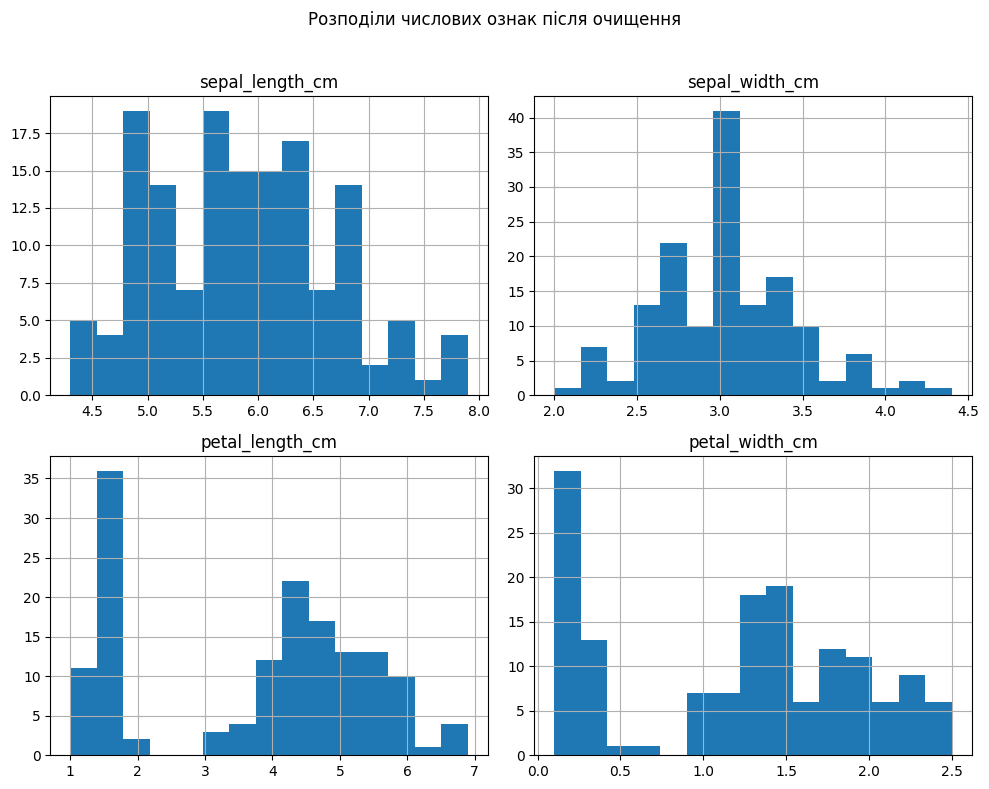

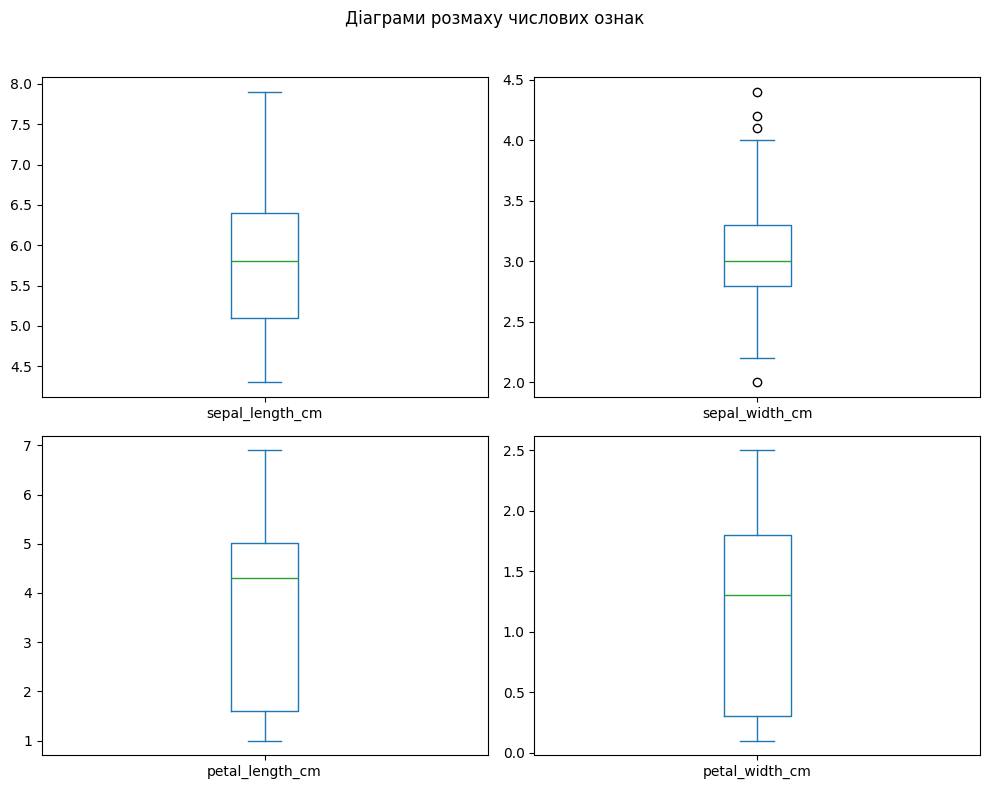

In [22]:
display(clean_df[numeric_columns].describe().T)

clean_df[numeric_columns].hist(bins=15, figsize=(10, 8))
plt.suptitle("Розподіли числових ознак після очищення")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

clean_df[numeric_columns].plot(
    kind="box", subplots=True, layout=(2, 2), figsize=(10, 8), sharex=False, sharey=False
)
plt.suptitle("Діаграми розмаху числових ознак")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

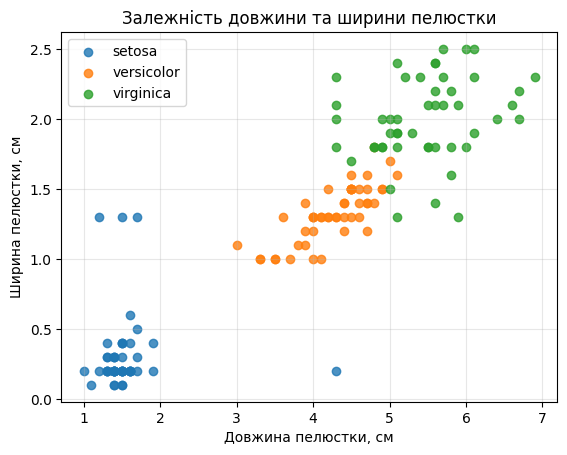

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
sepal_length_cm,1.000,-0.099,0.821,0.767
sepal_width_cm,-0.099,1.000,-0.379,-0.336
petal_length_cm,0.821,-0.379,1.000,0.920
petal_width_cm,0.767,-0.336,0.920,1.000


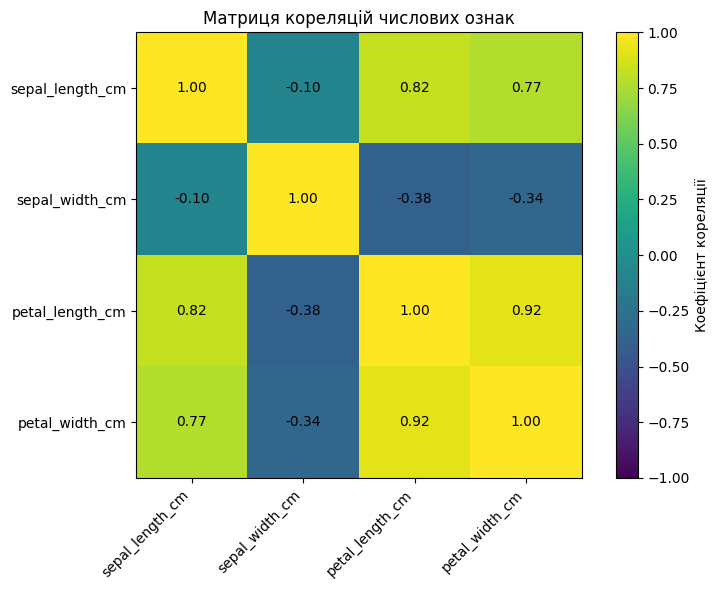

In [23]:
# Залежність довжини та ширини пелюстки
for species_name, group in clean_df.groupby("species"):
    plt.scatter(
        group["petal_length_cm"],
        group["petal_width_cm"],
        label=species_name,
        alpha=0.8
    )
plt.title("Залежність довжини та ширини пелюстки")
plt.xlabel("Довжина пелюстки, см")
plt.ylabel("Ширина пелюстки, см")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Обчислення матриці кореляцій
correlation_matrix = clean_df[numeric_columns].corr()
display(correlation_matrix.round(3))

# Побудова матриці кореляцій через imshow
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1
)
ax.set_xticks(range(len(numeric_columns)))
ax.set_yticks(range(len(numeric_columns)))
ax.set_xticklabels(numeric_columns, rotation=45, ha="right")
ax.set_yticklabels(numeric_columns)

for row_index in range(len(numeric_columns)):
    for column_index in range(len(numeric_columns)):
        ax.text(
            column_index,
            row_index,
            f"{correlation_matrix.iloc[row_index, column_index]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(image, ax=ax, label="Коефіцієнт кореляції")
ax.set_title("Матриця кореляцій числових ознак")
plt.tight_layout()
plt.show()

## 7. Кодування категоріальних ознак та розбиття вибірки

In [24]:
encoded_df = pd.get_dummies(
    clean_df,
    columns=["measurement_device"],
    dtype=int
)

class_mapping = {
    "setosa": 0,
    "versicolor": 1,
    "virginica": 2
}
encoded_df["species_code"] = encoded_df["species"].map(class_mapping)

X = encoded_df.drop(columns=["species", "species_code"])
y = encoded_df["species_code"]

print("Розмір матриці ознак X:", X.shape)
print("Розмір цільової змінної y:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Розмір матриці ознак X: (148, 7)
Розмір цільової змінної y: (148,)
X_train: (118, 7)
X_test: (30, 7)


In [25]:
reverse_class_mapping = {
    value: key for key, value in class_mapping.items()
}

train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

class_split_report = pd.DataFrame(
    {
        "train_count": train_counts,
        "test_count": test_counts
    }
)
class_split_report.index = [
    reverse_class_mapping[index] for index in class_split_report.index
]

class_split_report["train_percent"] = (
    class_split_report["train_count"] / class_split_report["train_count"].sum() * 100
).round(2)
class_split_report["test_percent"] = (
    class_split_report["test_count"] / class_split_report["test_count"].sum() * 100
).round(2)

display(class_split_report)

# Демонстрація випадкового розбиття без стратифікації
_, _, y_train_random, y_test_random = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7
)

random_split_report = pd.DataFrame(
    {
        "train_percent": (
            y_train_random
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        ),
        "test_percent": (
            y_test_random
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2)
        )
    }
)
random_split_report.index = [
    reverse_class_mapping[index] for index in random_split_report.index
]
display(random_split_report)

,train_count,test_count,train_percent,test_percent
setosa,40,10,33.90,33.33
versicolor,39,10,33.05,33.33
virginica,39,10,33.05,33.33


,train_percent,test_percent
setosa,36.44,23.33
versicolor,31.36,40.00
virginica,32.20,36.67


In [26]:
preprocessing_summary = pd.DataFrame([
    {
        "stage": "Початковий пошкоджений набір",
        "row_count": len(raw_df),
        "missing_count": int(raw_df.isna().sum().sum()),
        "duplicate_count": int(raw_df.duplicated().sum())
    },
    {
        "stage": "Після видалення дублікатів",
        "row_count": rows_after_duplicates,
        "missing_count": None,
        "duplicate_count": 0
    },
    {
        "stage": "Після очищення",
        "row_count": len(clean_df),
        "missing_count": int(clean_df.isna().sum().sum()),
        "duplicate_count": int(clean_df.duplicated().sum())
    },
    {
        "stage": "Навчальна вибірка",
        "row_count": len(X_train),
        "missing_count": int(X_train.isna().sum().sum()),
        "duplicate_count": int(X_train.duplicated().sum())
    },
    {
        "stage": "Тестова вибірка",
        "row_count": len(X_test),
        "missing_count": int(X_test.isna().sum().sum()),
        "duplicate_count": int(X_test.duplicated().sum())
    }
])

clean_df.to_csv(CLEANED_PATH, index=False)
X_train.to_csv(X_TRAIN_PATH, index=False)
X_test.to_csv(X_TEST_PATH, index=False)
y_train.rename("species_code").to_csv(Y_TRAIN_PATH, index=False)
y_test.rename("species_code").to_csv(Y_TEST_PATH, index=False)
preprocessing_summary.to_csv(SUMMARY_PATH, index=False)

with open(CLASS_MAPPING_PATH, "w", encoding="utf-8") as file:
    json.dump(class_mapping, file, ensure_ascii=False, indent=4)

# Автоматичні перевірки (asserts)
assert clean_df.isna().sum().sum() == 0, "В очищеній таблиці залишилися пропуски."
assert clean_df.duplicated().sum() == 0, "В очищеній таблиці залишилися дублікати."
assert set(clean_df["species"].unique()) == {"setosa", "versicolor", "virginica"}
assert all(pd.api.types.is_numeric_dtype(clean_df[col]) for col in numeric_columns)
assert (clean_df[numeric_columns] > 0).all().all(), "Залишилися фізично неможливі значення."
assert len(X_train) + len(X_test) == len(X)
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0

print("Усі основні перевірки виконано успішно!")

Усі основні перевірки виконано успішно!


# Висновки
Під час виконання практичної роботи №2 було проведено дослідницький аналіз і повноцінну підготовку набору даних Iris до машинного навчання.
- Створено пошкоджений набір `iris_dirty.csv`, виявлено та усунено пропуски, дублікати та аномальні значення за допомогою міжквартильного розмаху ($IQR$).
- Виправлено типи даних, стандартизовано категоріальні ознаки пристрою та видів ірису.
- Заповнено пропуски числових ознак медіанами, а категоріальних — модою.
- Закодовано категоріальні ознаки методом one-hot та сформовано навчальну і тестову вибірки у співвідношенні 80%/20% зі стратифікацією.
- Усі підготовлені файли та звіти збережено у відповідних директоріях на Google Drive.

## 8. Додаткове завдання (Варіант 2: Порівняння середнього і медіани)

In [27]:
mean_median_comparison = pd.DataFrame(
    {
        "mean": clean_df[numeric_columns].mean(),
        "median": clean_df[numeric_columns].median()
    }
)
mean_median_comparison["difference"] = (
    mean_median_comparison["mean"] - mean_median_comparison["median"]
)
display(mean_median_comparison)

,mean,median,difference
sepal_length_cm,5.850676,5.8,0.050676
sepal_width_cm,3.044595,3.0,0.044595
petal_length_cm,3.731757,4.3,-0.568243
petal_width_cm,1.20473,1.3,-0.09527


### Пояснення щодо асиметрії розподілу:
- Розподіл ознаки вважається асиметричним, якщо її середнє арифметичне (`mean`) відрізняється від медіани (`median`).
- У нашому наборі даних для більшості числових ознак (`sepal_length_cm`, `sepal_width_cm`, `petal_length_cm`, `petal_width_cm`) різниця між середнім і медіаною є дуже невеликою, що свідчить про близький до нормального (симетричний) розподіл очищених даних.
- Незначні відхилення (асиметрія) можуть спостерігатися в ознаках, де наявні специфічні природні групи значень (наприклад, менші пелюстки у виду *Setosa* та більші у *Virginica*).